# Higgs Boson Machine Learning Challenge — signal vs background

**Goal.** Classify ATLAS collision events as signal (`s`, Higgs → ττ) or background (`b`) and evaluate with the competition metric, **Approximate Median Significance (AMS)**, not accuracy.

**What this notebook does:** data understanding → EDA → preprocessing → fair validation → baselines → experiments (each with a stated question) → error analysis → final model → submission file.



## 1. Setup

In [2]:
import sys, time, warnings, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve
from sklearn.inspection import permutation_importance
from scipy.stats import rankdata
import lightgbm as lgb

from higgs import (load_data, FEATURES, MISSING, ams, ams_curve, best_ams_threshold, honest_ams,
                   smooth_ams_curve, best_smooth_ams)
from higgs.metrics import ams_reference, ams_from_selection
from higgs.features import prepare, add_physics_features, structural_missing_cols

SEED = 42
np.random.seed(SEED)
FIG = Path.cwd().parent / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
def savefig(name): plt.savefig(FIG / f"{name}.png"); plt.show()
print("random seed:", SEED)

random seed: 42


## 2. Data understanding

In [3]:
train, test, info = load_data()
print("train:", train.shape, "| test:", test.shape)
display(train.head(3))

train: (250000, 33) | test: (550000, 31)


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,...,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,...,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.002653,s
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,...,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,2.233584,b
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,...,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,2.347389,b


In [4]:
print("dtypes:", train[FEATURES].dtypes.value_counts().to_dict())
print("duplicated feature rows:", train.duplicated(subset=FEATURES).sum(), "| duplicated EventId:", train.EventId.duplicated().sum())
print("true NaN values:", int(train.isna().sum().sum()), "(missing data is encoded as -999.0, not NaN)")
print("PRI_jet_num values:", sorted(train.PRI_jet_num.unique()))
display(train[FEATURES].replace(MISSING, np.nan).describe().T[["count","mean","std","min","50%","max"]].round(2))

dtypes: {dtype('float64'): 29, dtype('int64'): 1}
duplicated feature rows: 0 | duplicated EventId: 0
true NaN values: 0 (missing data is encoded as -999.0, not NaN)
PRI_jet_num values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


,count,mean,std,min,50%,max
DER_mass_MMC,211886.0,121.86,57.30,9.04,112.41,1192.03
DER_mass_transverse_met_lep,250000.0,49.24,35.34,0.00,46.52,690.08
DER_mass_vis,250000.0,81.18,40.83,6.33,73.75,1349.35
DER_pt_h,250000.0,57.90,63.66,0.00,38.47,2835.00
DER_deltaeta_jet_jet,72543.0,2.40,1.74,0.00,2.11,8.50
DER_mass_jet_jet,72543.0,371.78,397.70,13.60,225.88,4974.98
DER_prodeta_jet_jet,72543.0,-0.82,3.58,-18.07,-0.24,16.69
DER_deltar_tau_lep,250000.0,2.37,0.78,0.21,2.49,5.68
DER_pt_tot,250000.0,18.92,22.27,0.00,12.32,2835.00
DER_sum_pt,250000.0,158.43,115.71,46.10,120.66,1852.46


,events,event_share,weight_sum,weight_share
Label,,,,
b,164333,0.65733,410999.84732,0.99832
s,85667,0.34267,691.98861,0.00168


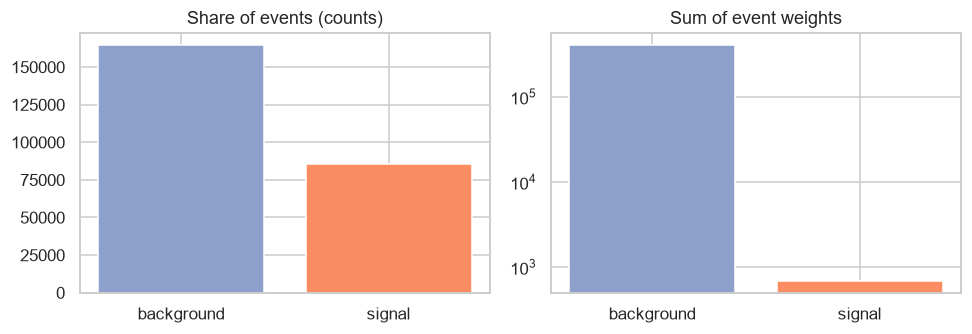

In [5]:
y = (train.Label == "s").values          # True = signal
w = train.Weight.values
cnt = train.Label.value_counts()
wsum = train.groupby("Label").Weight.sum()
tab = pd.DataFrame({"events": cnt, "event_share": cnt/cnt.sum(), "weight_sum": wsum, "weight_share": wsum/wsum.sum()})
display(tab.round(5))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(["background","signal"], [cnt["b"], cnt["s"]], color=["#8da0cb","#fc8d62"]); ax[0].set_title("Share of events (counts)")
ax[1].bar(["background","signal"], [wsum["b"], wsum["s"]], color=["#8da0cb","#fc8d62"]); ax[1].set_title("Sum of event weights"); ax[1].set_yscale("log")
for a in ax: a.set_ylabel("")
plt.tight_layout(); savefig("01_counts_vs_weights")

**What it shows.** By *count* the data is moderately imbalanced: 34.3 % signal (85,667 events) vs 65.7 % background (164,333). By *weight* the picture is completely different: signal carries only ≈ 0.17 % of the total weight (≈ 692 vs ≈ 411,000). The weights express the expected number of events in real data, where genuine Higgs events are extremely rare compared with background.

**Why it matters.** (i) AMS is computed with weights, so a single background event that is wrongly selected costs far more than a correctly selected signal event gains. (ii) A classifier trained with raw weights sees almost only background; a classifier trained without weights sees a 'friendly' 1 : 2 problem. Neither is automatically right for AMS — §7.2 tests it. (iii) **Caveat:** here the weights are a *proxy* (one constant per class), so the 1 : 310 per-event weight ratio is exactly the class ratio; in the official file the weights also vary inside each class.

## 3. Exploratory data analysis
Every plot below starts with a question.

### Q1 — How often is `-999` present, and does it differ between signal and background?

,all %,signal %,background %
DER_deltaeta_jet_jet,71.0,62.1,75.6
DER_mass_jet_jet,71.0,62.1,75.6
DER_prodeta_jet_jet,71.0,62.1,75.6
PRI_jet_subleading_phi,71.0,62.1,75.6
DER_lep_eta_centrality,71.0,62.1,75.6
PRI_jet_subleading_eta,71.0,62.1,75.6
PRI_jet_subleading_pt,71.0,62.1,75.6
PRI_jet_leading_eta,40.0,29.8,45.3
PRI_jet_leading_pt,40.0,29.8,45.3
PRI_jet_leading_phi,40.0,29.8,45.3


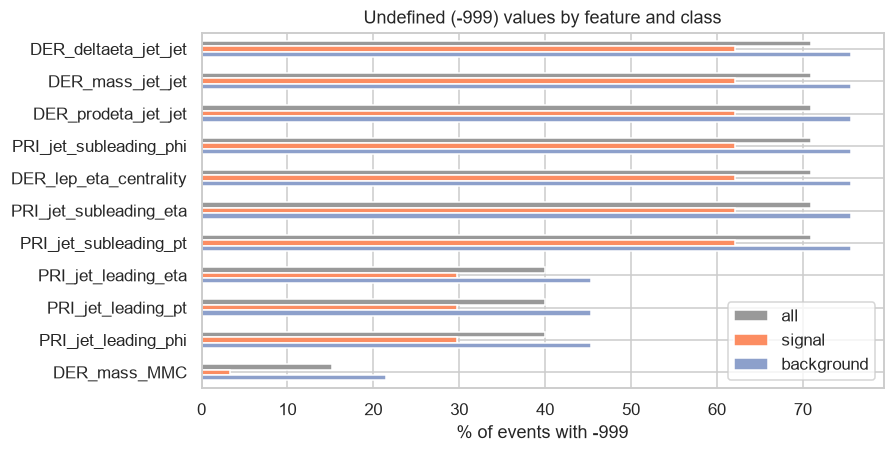

In [5]:
M = (train[FEATURES] == MISSING)
miss = pd.DataFrame({"all": M.mean(), "signal": M[y].mean(), "background": M[~y].mean()})
miss = miss[miss["all"] > 0].sort_values("all", ascending=False)
display((miss*100).round(1).rename(columns=lambda c: c+" %"))
ax = (miss*100).plot.barh(figsize=(8, 4.2), color=["#999999","#fc8d62","#8da0cb"]); ax.invert_yaxis()
ax.set_xlabel("% of events with -999"); ax.set_title("Undefined (-999) values by feature and class")
savefig("02_missing_by_class")

**What it shows.** Seven features are undefined for 71 % of events, three jet-leading features for 40 %, and `DER_mass_MMC` for 15 %. The share of `-999` differs a lot between classes: e.g. the two-jet features are undefined for 76 % of background but only 62 % of signal, and `DER_mass_MMC` is undefined for 21.5 % of background but only 3.3 % of signal.

**Why it matters.** The *fact* that a value is missing is itself informative (an event with `DER_mass_MMC = -999` is signal only 7.4 % of the time vs 39 % when it is defined). Replacing `-999` blindly (e.g. with the mean) would destroy this information and create a fake spike in the distribution (§7.1).

### Q2 — Is the missingness random, or determined by something physical?

In [6]:
jet_cols_2 = ["DER_mass_jet_jet","DER_deltaeta_jet_jet","DER_prodeta_jet_jet","DER_lep_eta_centrality",
              "PRI_jet_subleading_pt","PRI_jet_subleading_eta","PRI_jet_subleading_phi"]
jet_cols_1 = ["PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi"]
g = train.groupby("PRI_jet_num")
pat = pd.DataFrame({
    "events": g.size(),
    "share undefined: 2-jet features": g.apply(lambda d: (d[jet_cols_2[0]] == MISSING).mean()),
    "share undefined: 1-jet features": g.apply(lambda d: (d[jet_cols_1[0]] == MISSING).mean()),
    "share undefined: DER_mass_MMC": g.apply(lambda d: (d["DER_mass_MMC"] == MISSING).mean()),
})
display(pat.round(3))
same = all(((train[c] == MISSING) == (train[jet_cols_2[0]] == MISSING)).all() for c in jet_cols_2)
print("All 7 'two-jet' features are undefined for exactly the same events:", same)
print("Those events are exactly the ones with PRI_jet_num < 2:", bool(((train[jet_cols_2[0]] == MISSING) == (train.PRI_jet_num < 2)).all()))

,events,share undefined: 2-jet features,share undefined: 1-jet features,share undefined: DER_mass_MMC
PRI_jet_num,,,,
0,99913,1.0,1.0,0.261
1,77544,1.0,0.0,0.098
2,50379,0.0,0.0,0.059
3,22164,0.0,0.0,0.067


All 7 'two-jet' features are undefined for exactly the same events: True
Those events are exactly the ones with PRI_jet_num < 2: True


**What it shows.** The missingness is *structural*, not random. All seven 'two-jet' features are undefined for exactly the events with fewer than two jets (`PRI_jet_num < 2`), and the three 'leading-jet' features are undefined exactly when there are no jets. This is physics: a jet-pair mass cannot exist without two jets. `DER_mass_MMC` is the exception — it can fail for any jet multiplicity (26 % of 0-jet events, 6–10 % otherwise) because the mass-reconstruction algorithm can fail.

**Why it matters.** `PRI_jet_num` already encodes most of the missingness pattern, so (a) explicit indicator columns add little for the jet features, and (b) dropping the sparse columns would throw away real information for the 2- and 3-jet events, where those features are well defined and discriminating. We test this instead of assuming it.

### Q3 — Does the signal fraction depend on the jet multiplicity or on whether the mass could be computed?

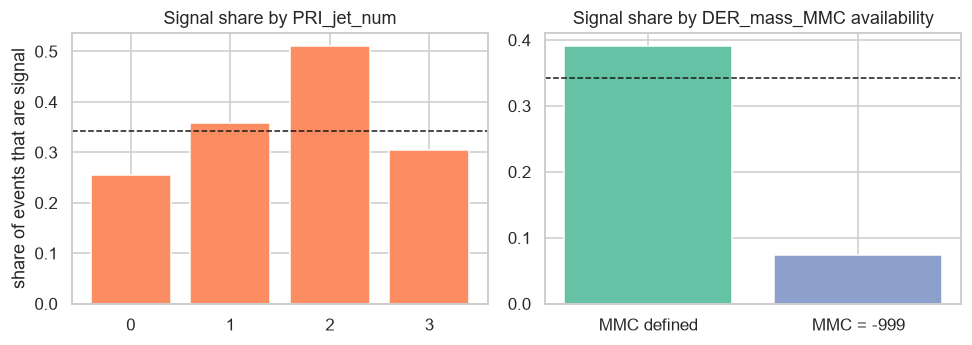

signal share overall 0.343 | MMC undefined: 0.074 | MMC defined: 0.391


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
sf = train.groupby("PRI_jet_num").Label.apply(lambda s: (s == "s").mean())
ax[0].bar(sf.index.astype(str), sf.values, color="#fc8d62"); ax[0].axhline(y.mean(), ls="--", c="k", lw=1)
ax[0].set_title("Signal share by PRI_jet_num"); ax[0].set_ylabel("share of events that are signal")
mm = train.DER_mass_MMC == MISSING
ax[1].bar(["MMC defined","MMC = -999"], [y[~mm].mean(), y[mm].mean()], color=["#66c2a5","#8da0cb"]); ax[1].axhline(y.mean(), ls="--", c="k", lw=1)
ax[1].set_title("Signal share by DER_mass_MMC availability")
plt.tight_layout(); savefig("03_signal_share")
print("signal share overall %.3f | MMC undefined: %.3f | MMC defined: %.3f" % (y.mean(), y[mm].mean(), y[~mm].mean()))

**What it shows.** The signal share rises from 25.5 % (0 jets) and 35.7 % (1 jet) to 51.1 % (2 jets), then falls to 30.4 % (3 jets). Events whose `DER_mass_MMC` is undefined are only 7.4 % signal, versus 39.1 % when it is defined.

**Why it matters.** Jet multiplicity and mass availability are strong, cheap cues. They suggest the data is really a mixture of different sub-populations (jet categories) with different class mixtures, which tree models can exploit by splitting on `PRI_jet_num` and on the missing marker.

### Q4 — Which features separate the classes, and what do their distributions look like?

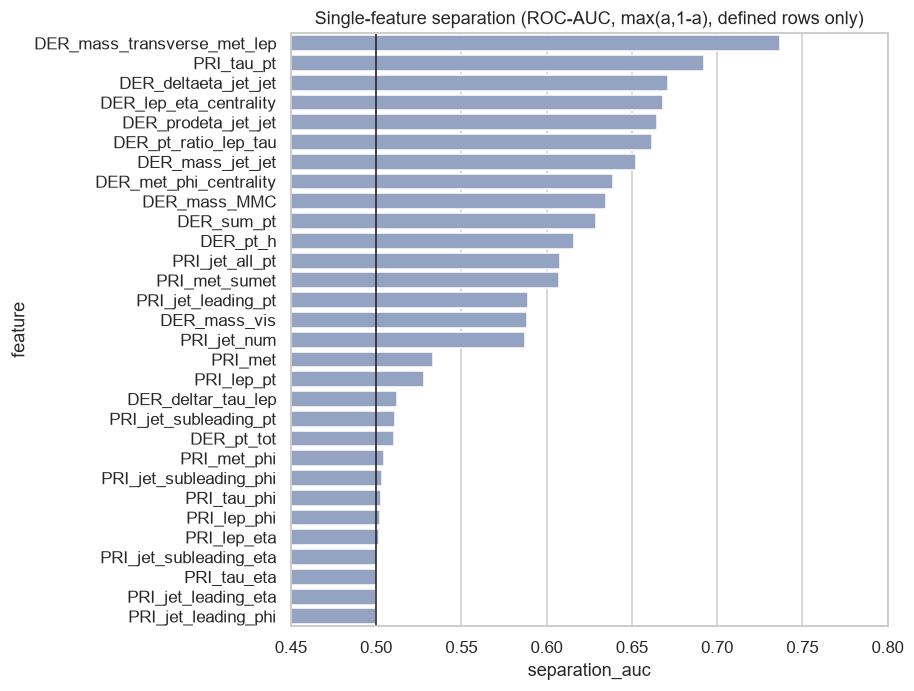

,feature,separation_auc,share_defined
1,DER_mass_transverse_met_lep,0.737,1.00
13,PRI_tau_pt,0.692,1.00
4,DER_deltaeta_jet_jet,0.671,0.29
12,DER_lep_eta_centrality,0.668,0.29
6,DER_prodeta_jet_jet,0.665,0.29
10,DER_pt_ratio_lep_tau,0.662,1.00
5,DER_mass_jet_jet,0.652,0.29
11,DER_met_phi_centrality,0.639,1.00


In [8]:
rows = []
for c in FEATURES:
    ok = train[c] != MISSING
    a = roc_auc_score(y[ok], train.loc[ok, c]); rows.append((c, max(a, 1 - a), ok.mean()))
sep = pd.DataFrame(rows, columns=["feature","separation_auc","share_defined"]).sort_values("separation_auc", ascending=False)
fig, ax = plt.subplots(figsize=(7, 7))
sns.barplot(data=sep, y="feature", x="separation_auc", color="#8da0cb", ax=ax); ax.axvline(0.5, c="k", lw=1)
ax.set_xlim(0.45, max(0.8, sep.separation_auc.max()+0.02)); ax.set_title("Single-feature separation (ROC-AUC, max(a,1-a), defined rows only)")
savefig("04_univariate_auc"); display(sep.head(8).round(3))

**What it shows.** Individually, no feature is strong: the best one-feature ROC-AUC is 0.74 (`DER_mass_transverse_met_lep`, lower for signal), followed by `PRI_tau_pt` (0.69) and the jet-pair variables (≈ 0.67). Angles and pseudorapidities (`*_phi`, `PRI_tau_eta`, `PRI_lep_eta`, `PRI_jet_*_eta`) are all at AUC ≈ 0.50, i.e. carry no information *on their own*.

**Caveat.** This ranking is monotonic. `DER_mass_MMC` only scores 0.64 here, yet we will see in §8.1 that it is by far the most important feature for the model. Reason: signal masses cluster near 125 GeV (a *peak*) while background is broad; a peak cannot be summarised by 'larger = more signal'.

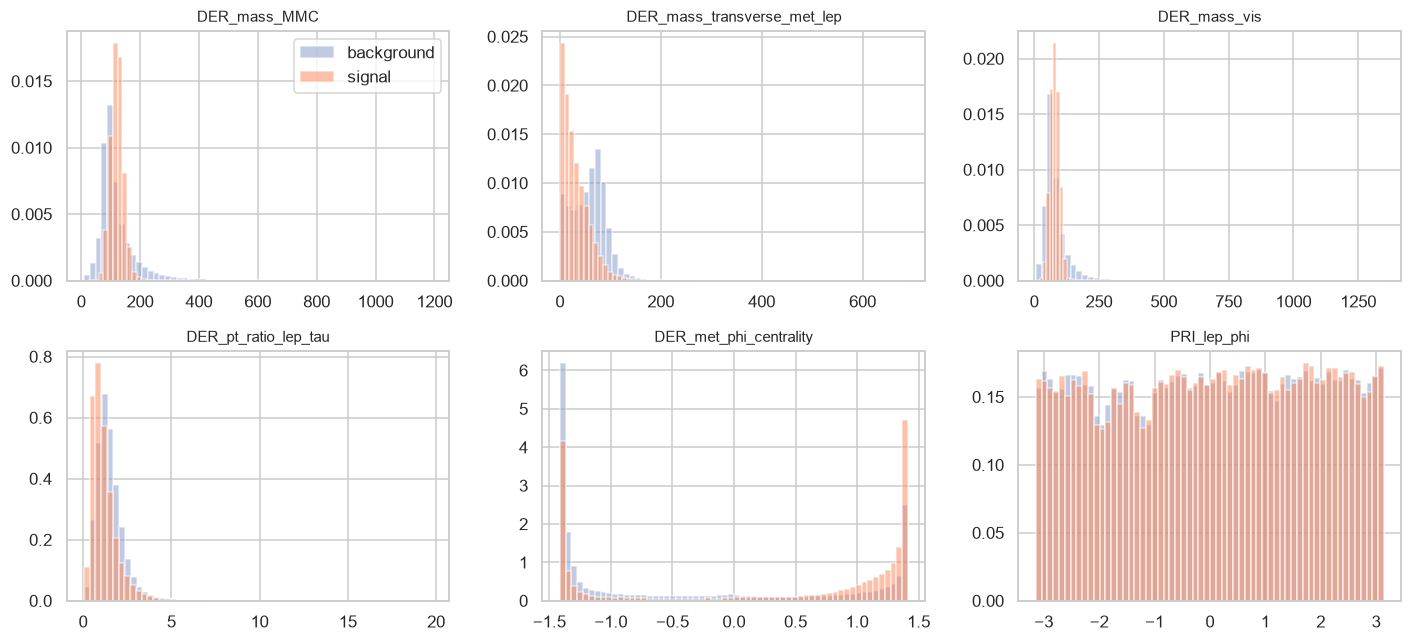

In [9]:
show = ["DER_mass_MMC","DER_mass_transverse_met_lep","DER_mass_vis","DER_pt_ratio_lep_tau","DER_met_phi_centrality","PRI_lep_phi"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for a, c in zip(axes.ravel(), show):
    d = train[train[c] != MISSING]
    for lab, col, nm in (("b", "#8da0cb", "background"), ("s", "#fc8d62", "signal")):
        a.hist(d.loc[d.Label == lab, c], bins=60, density=True, alpha=.55, color=col, label=nm)
    a.set_title(c, fontsize=10)
axes[0, 0].legend(); plt.tight_layout(); savefig("05_distributions")

**What it shows.** `DER_mass_MMC` (defined rows only): background is broad and right-skewed (std ≈ 70 GeV), signal is a narrow bump around 120–125 GeV (std ≈ 28 GeV) — the Higgs mass peak. `DER_mass_transverse_met_lep` is much lower for signal (median 24 vs 61 GeV). `DER_mass_vis` is slightly higher for signal (median 79 vs 70 GeV). `PRI_lep_phi` (an azimuth angle) is flat and identical for both classes.

**Why it matters.** The most useful variables differ in *shape* (a peak vs a long tail), not just in mean — a hint that non-linear models should beat a linear one by a large margin. A flat azimuth angle has no discriminating power on its own, consistent with the rotational symmetry of the detector.

### Q5 — Which features are redundant? (correlations, `-999` treated as missing)

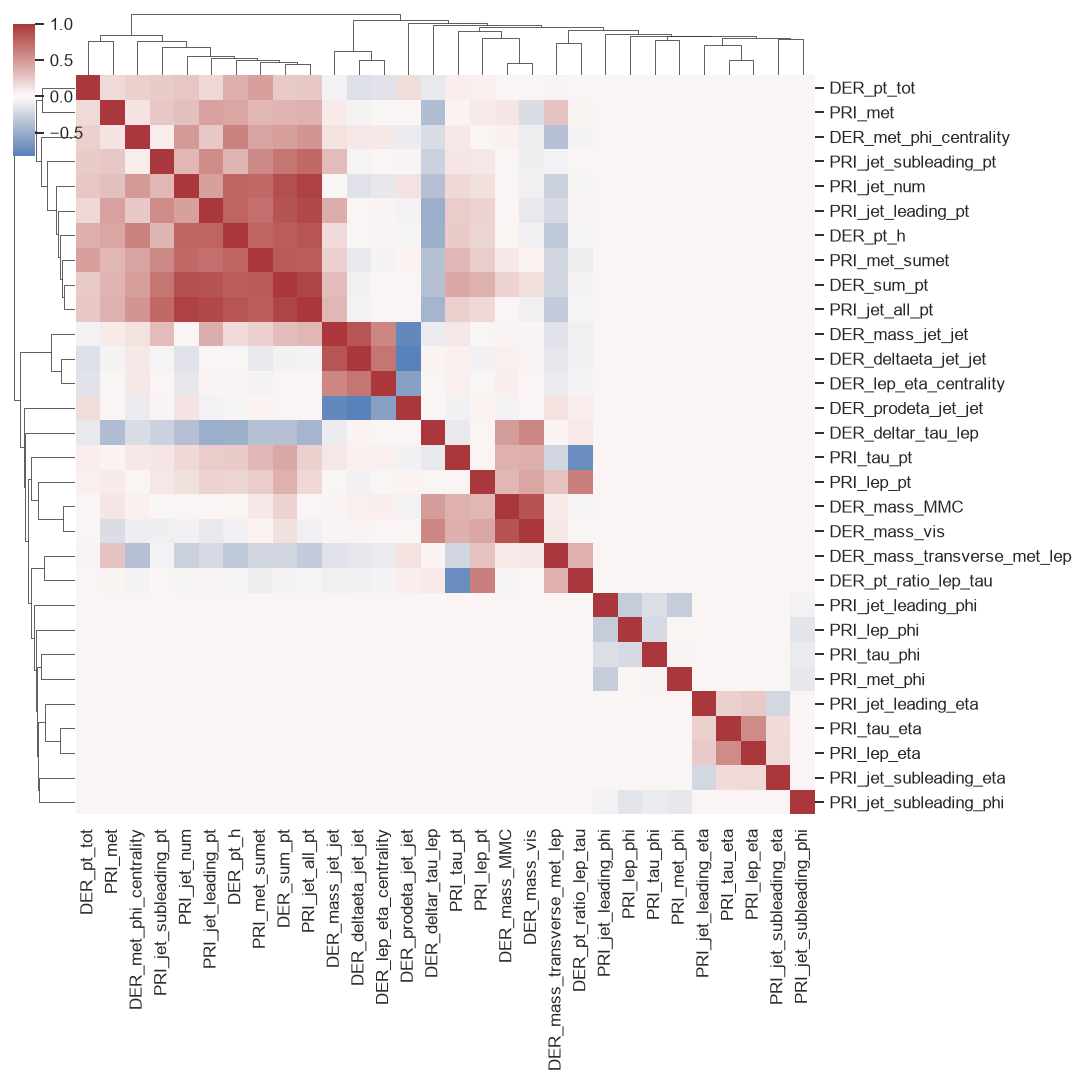

,level_0,level_1,rho
689,PRI_jet_num,PRI_jet_all_pt,0.949
299,DER_sum_pt,PRI_jet_all_pt,0.930
719,PRI_jet_leading_pt,PRI_jet_all_pt,0.906
292,DER_sum_pt,PRI_jet_num,0.876
293,DER_sum_pt,PRI_jet_leading_pt,0.857
2,DER_mass_MMC,DER_mass_vis,0.855
119,DER_pt_h,PRI_jet_all_pt,0.849
125,DER_deltaeta_jet_jet,DER_mass_jet_jet,0.848
126,DER_deltaeta_jet_jet,DER_prodeta_jet_jet,-0.820
291,DER_sum_pt,PRI_met_sumet,0.820


In [10]:
C = train[FEATURES].replace(MISSING, np.nan).corr(method="spearman")
order = sns.clustermap(C, cmap="vlag", center=0, figsize=(10, 10), dendrogram_ratio=.08, cbar_pos=(.02, .85, .02, .12)).dendrogram_row.reordered_ind
plt.savefig(FIG / "06_correlation_clustermap.png"); plt.show()
pairs = (C.where(np.triu(np.ones(C.shape, bool), 1)).stack().rename("rho").reset_index())
pairs = pairs[pairs.rho.abs() > 0.8].sort_values("rho", key=abs, ascending=False)
display(pairs.round(3))

**What it shows.** Strong redundancy exists, mostly for obvious reasons: `PRI_jet_all_pt` is ~0.95 correlated with `PRI_jet_num` and ~0.93 with `DER_sum_pt` (it is a sum over jets); `DER_mass_MMC` and `DER_mass_vis` correlate at 0.86 (both are masses of the same τ–lepton system); `DER_deltaeta_jet_jet` correlates with `DER_mass_jet_jet` (0.85) and `DER_prodeta_jet_jet` (−0.82).

**Decision.** We do **not** drop correlated features automatically. Trees and boosting handle correlation without trouble; for the logistic regression, `C = 1` regularisation keeps coefficients stable. The importance and subset experiments (§7.4, §8.1) check whether any of them is actually unnecessary.

## 4. Data preparation & validation design

**Decisions (each one is tested later in the experiments, not assumed):**

1. `EventId`, `Weight`, `Label` are **never** in the feature matrix. `Weight` is used separately, for evaluation and (in one experiment) for training.
2. `-999` is **not** an ordinary number. `features.prepare()` offers three treatments: `keep` (leave -999, which tree models can isolate with a split), `nan` (→ NaN; histogram gradient boosting and LightGBM use it natively) and `indicator` (NaN + a 0/1 "undefined" column). For linear models we use median imputation (+ optional indicators) *inside the pipeline*, so the median is learned from training folds only.
3. Linear models are scaled (`StandardScaler`); tree models are not.
4. No feature is dropped just for being sparse or correlated — dropping is tested as an experiment (§7).
5. **Validation:** one stratified 80/20 split (seed 42) used for *every* model, so comparisons are fair; key conclusions are re-checked on two more seeds (§7.8). The test file is never used for decisions.
6. **Weights in the metric:** validation weights are multiplied by `N_total / N_validation` so `s` and `b` are on the scale of the full 250 000-event sample (AMS depends on that scale).
7. **Threshold & a noisy metric.** AMS is maximised over `q`, the *fraction of events labelled signal* (equivalently a score cut). Two problems: (i) picking the best cut on the same validation set that reports the AMS is optimistic; (ii) with a few heavy background events near the top of the ranking, one extra false positive can change the maximum a lot (we saw this in a first run: identical AMS values for different models, and swings between splits). So we report three numbers:
   * `AMS_oracle` — best cut on the validation set itself (optimistic, spiky);
   * `AMS_honest` — cut chosen on one half of validation, scored on the other half, averaged;
   * **`AMS_smooth`** — maximum of the *bootstrap-averaged* AMS-vs-q curve (30 resamples). Least spiky, **our main comparison metric**, together with ROC-AUC. It is still computed on the validation set, so it is mildly optimistic in absolute terms; use it to *compare* models, not as a performance promise.

In [11]:
idx = np.arange(len(train))
i_tr, i_va = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
SCALE = len(train) / len(i_va)
print("train %d | valid %d | signal share train %.4f valid %.4f (full %.4f)" % (len(i_tr), len(i_va), y[i_tr].mean(), y[i_va].mean(), y.mean()))
y_va, w_va = y[i_va], w[i_va]

# --- check our AMS against the reference implementation of the competition formula
for s_, b_ in [(10, 100), (50, 1000), (200, 4000), (0.0, 50)]:
    assert math.isclose(ams(s_, b_), ams_reference(s_, b_), rel_tol=1e-12)
print("ams() == reference formula on test points. AMS(s=100,b=1000) = %.4f" % ams(100, 1000))

# weights for training experiments: none | raw (mean 1) | balanced (each class sums to half of the total)
W_MODES = {
    "none": None,
    "raw": w / w.mean(),
    "balanced": np.where(y, 0.5 / w[y].sum(), 0.5 / w[~y].sum()) * len(y),
}
for k, v in W_MODES.items():
    if v is not None: print(f"{k:9s} signal weight share = {v[y].sum()/v.sum():.4f}")

train 200000 | valid 50000 | signal share train 0.3427 valid 0.3427 (full 0.3427)
ams() == reference formula on test points. AMS(s=100,b=1000) = 3.0967
raw       signal weight share = 0.0017
balanced  signal weight share = 0.9968


In [12]:
RESULTS, PRED = [], {}
def evaluate(exp, prep, model_name, X, model, wmode="none", note="", store=True, fit_kw=None, tr=None, va=None, seed_tag=None):
    """Fit on `tr`, score on `va` (defaults: global split). Returns dict and logs it."""
    tr = i_tr if tr is None else tr; va = i_va if va is None else va
    sw = W_MODES[wmode]; kw = {} if sw is None else {fit_kw or "sample_weight": sw[tr]}
    t0 = time.time(); model.fit(X.iloc[tr], y[tr], **kw); dt = time.time() - t0
    p = model.predict_proba(X.iloc[va])[:, 1]
    sc_ = len(train) / len(va)
    r = dict(experiment=exp, preprocessing=prep, model=model_name, weights=wmode,
             auc=roc_auc_score(y[va], p),
             ams_oracle=best_ams_threshold(y[va], p, w[va], sc_)[1],
             ams_honest=honest_ams(y[va], p, w[va], sc_),
             ams_smooth=best_smooth_ams(y[va], p, w[va], sc_)[1],
             acc_at_0_5=accuracy_score(y[va], p >= .5), fit_s=round(dt, 1), what_changed=note)
    if seed_tag is None:
        RESULTS.append(r)
        if store: PRED[f"{exp}|{model_name}|{prep}|{wmode}"] = p
    return r, p
def show_results(exps=None):
    d = pd.DataFrame(RESULTS)
    if exps is not None: d = d[d.experiment.isin(exps)]
    return d[["experiment","preprocessing","model","weights","auc","ams_smooth","ams_honest","ams_oracle","acc_at_0_5","what_changed"]].round(4)

In [13]:
# Feature matrices (no EventId / Weight / Label)
X_keep = prepare(train, "keep"); X_nan = prepare(train, "nan"); X_ind = prepare(train, "indicator")
print(X_keep.shape, X_nan.shape, X_ind.shape, "| forbidden columns present:",
      [c for c in ("EventId","Weight","Label") if c in X_keep.columns])

NUM = [c for c in FEATURES if c != "PRI_jet_num"]
def make_lr(indicator=False, C=1.0):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=indicator)),
                          ("sc", StandardScaler())]), NUM),
        ("jet", OneHotEncoder(categories=[[0, 1, 2, 3]], handle_unknown="ignore"), ["PRI_jet_num"]),
    ])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, max_iter=2000, random_state=SEED))])
def make_hgb(**kw):
    p = dict(max_iter=250, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0,
             early_stopping=False, random_state=SEED); p.update(kw)
    return HistGradientBoostingClassifier(**p)
def make_rf(**kw):
    p = dict(n_estimators=120, min_samples_leaf=10, max_features="sqrt", n_jobs=2, random_state=SEED); p.update(kw)
    return RandomForestClassifier(**p)
def make_et(**kw):
    p = dict(n_estimators=120, min_samples_leaf=10, max_features="sqrt", n_jobs=2, random_state=SEED); p.update(kw)
    return ExtraTreesClassifier(**p)
def make_lgb(**kw):
    p = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.8, reg_lambda=1.0, n_jobs=2, random_state=SEED, verbose=-1); p.update(kw)
    return lgb.LGBMClassifier(**p)
# note: fit_kw for pipelines routes sample_weight to the final step
LR_FIT = "lr__sample_weight"

(250000, 30) (250000, 30) (250000, 41) | forbidden columns present: []


## 5. Baselines

In [14]:
r = []
for name, strat in (("Dummy (most frequent)", "prior"), ("Dummy (stratified random)", "stratified")):
    evaluate("0 baseline", "-", name, X_keep, DummyClassifier(strategy=strat, random_state=SEED), note="no learning")
# what if we call *every* event signal?  (s = all signal weight, b = all background weight)
print("AMS of labelling every event as signal: %.3f" % ams(w[y].sum(), w[~y].sum()))
print("accuracy of always predicting background: %.4f" % (1 - y.mean()))
evaluate("0 baseline", "median impute + scale + one-hot jets", "Logistic Regression", X_nan, make_lr(indicator=False), note="linear baseline")
evaluate("0 baseline", "keep -999", "Decision Tree (depth 8)", X_keep, DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED), note="single tree")
evaluate("0 baseline", "keep -999", "Random Forest", X_keep, make_rf(), note="bagged trees")
evaluate("0 baseline", "keep -999", "Extra Trees", X_keep, make_et(), note="randomised splits")
evaluate("0 baseline", "NaN native", "HistGradientBoosting", X_nan, make_hgb(), note="boosted trees")
evaluate("0 baseline", "NaN native", "LightGBM", X_nan, make_lgb(), note="boosted trees (extension)")
show_results(["0 baseline"])

AMS of labelling every event as signal: 1.079
accuracy of always predicting background: 0.6573


,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
0,0 baseline,-,Dummy (most frequent),none,0.5000,0.6835,1.0840,1.0840,0.6573,no learning
1,0 baseline,-,Dummy (stratified random),none,0.5008,0.6782,1.0839,1.0840,0.5509,no learning
2,0 baseline,median impute + scale + one-hot jets,Logistic Regression,none,0.8146,2.0645,2.0370,2.0767,0.7510,linear baseline
3,0 baseline,keep -999,Decision Tree (depth 8),none,0.8816,2.9092,2.9245,2.9270,0.8179,single tree
4,0 baseline,keep -999,Random Forest,none,0.9053,3.4208,3.3940,3.4465,0.8377,bagged trees
5,0 baseline,keep -999,Extra Trees,none,0.8890,3.1455,3.0912,3.1737,0.8208,randomised splits
6,0 baseline,NaN native,HistGradientBoosting,none,0.9093,3.4698,3.4760,3.5137,0.8416,boosted trees
7,0 baseline,NaN native,LightGBM,none,0.9099,3.5102,3.3603,3.5343,0.8422,boosted trees (extension)


**Reading the table.** Both dummies have ROC-AUC 0.50 (no learning). Their AMS is ≈ 1.08, which is simply the AMS of calling *every* event signal. Logistic regression (AUC 0.815, AMS ≈ 1.6) is only marginally better on AMS despite a decent AUC. Moving to non-linear trees is the big step: a single depth-8 tree reaches AUC 0.882, random forest 0.905, histogram gradient boosting 0.909 and LightGBM 0.910.

**Observations worth keeping.** (1) The jump from linear to tree-based models is far larger than any difference *between* tree models — the signal lives in non-linear structure (mass peaks, jet-dependent regimes). (2) The AUC ranking and the AMS ranking do not fully agree: Extra Trees has a lower AUC than Random Forest (0.889 vs 0.905) but a higher AMS. We return to this in §7.7.

## 6. The metric: AMS, thresholds, and why accuracy is not enough
Question: **does a better ranking (ROC-AUC) always mean a better AMS, and where should the cut be?**

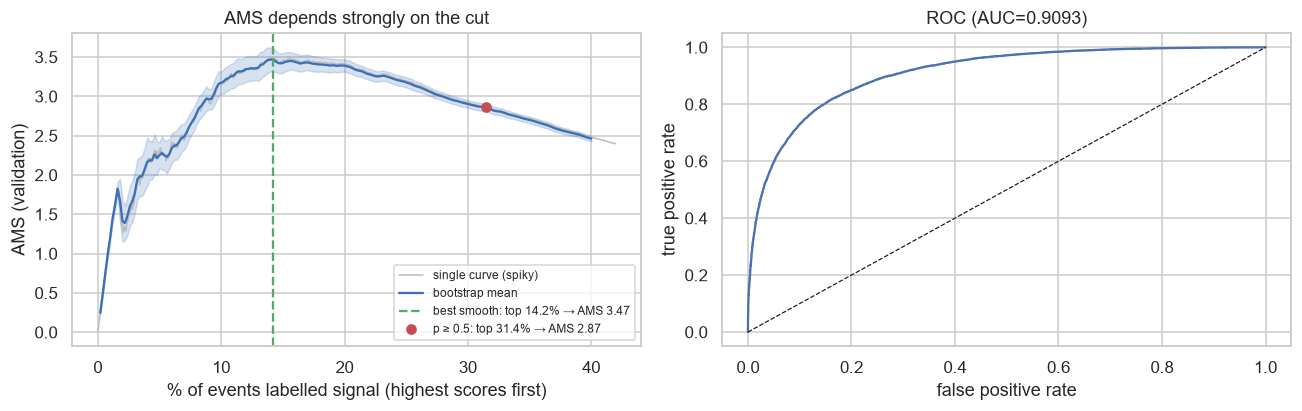

accuracy at p>=0.5: 0.8416 | accuracy at the AMS-best cut: 0.7796 | accuracy of 'always background': 0.6573
at the AMS-best cut: signal recall 0.386, background events selected: 493 of 32867


In [15]:
p = PRED["0 baseline|HistGradientBoosting|NaN native|none"]
thr, a, frac = ams_curve(y_va, p, w_va, SCALE, 1500)
qg, mq, sq = smooth_ams_curve(y_va, p, w_va, SCALE)
bi = int(np.argmax(mq)); q_best = qg[bi]
sel05 = p >= 0.5; ams05 = ams_from_selection(y_va, sel05, w_va, SCALE)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
m_ = frac <= .42
ax[0].plot(frac[m_]*100, a[m_], c="#bbbbbb", lw=1, label="single curve (spiky)")
ax[0].plot(qg*100, mq, c="#3b6fb6", label="bootstrap mean"); ax[0].fill_between(qg*100, mq-sq, mq+sq, color="#3b6fb6", alpha=.2)
ax[0].axvline(q_best*100, c="g", ls="--", label=f"best smooth: top {q_best*100:.1f}% → AMS {mq[bi]:.2f}")
ax[0].scatter([sel05.mean()*100], [ams05], c="r", zorder=5, label=f"p ≥ 0.5: top {sel05.mean()*100:.1f}% → AMS {ams05:.2f}")
ax[0].set_xlabel("% of events labelled signal (highest scores first)"); ax[0].set_ylabel("AMS (validation)"); ax[0].legend(fontsize=8); ax[0].set_title("AMS depends strongly on the cut")
fpr, tpr, _ = roc_curve(y_va, p); ax[1].plot(fpr, tpr); ax[1].plot([0,1],[0,1],"k--",lw=.8)
ax[1].set_title("ROC (AUC=%.4f)" % roc_auc_score(y_va, p)); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
plt.tight_layout(); savefig("07_ams_vs_threshold")
sel_b = p >= np.quantile(p, 1 - q_best)
print("accuracy at p>=0.5: %.4f | accuracy at the AMS-best cut: %.4f | accuracy of 'always background': %.4f" %
      (accuracy_score(y_va, sel05), accuracy_score(y_va, sel_b), 1 - y_va.mean()))
print("at the AMS-best cut: signal recall %.3f, background events selected: %d of %d" % (sel_b[y_va].mean(), int((sel_b & ~y_va).sum()), int((~y_va).sum())))

**What it shows.** AMS depends dramatically on where we cut. With the (proxy) weights the best smoothed cut labels only the top **1.2 %** of validation events as signal (AMS ≈ 5.98), a region with practically no background. The classifier's default `p ≥ 0.5` labels 31.4 % of events as signal and gives AMS ≈ **2.49** (red dot) — less than half. The single-cut curve (grey) is spiky because one extra background event moves it; the bootstrap mean (blue) is smoother, but even so the peak on this 50,000-event validation set is narrow and is followed by a dip, so the *exact* best cut is uncertain (on the 250,000 out-of-fold predictions in §9 the plateau is wider).

**Accuracy is the wrong target.** Accuracy at `p ≥ 0.5` is 0.842, but the AMS-best cut has accuracy 0.669, barely above the 0.657 obtained by *always predicting background*: it recovers only 3.5 % of the signal and selects none of the 32,867 background events. Two completely different operating points — and the lower-accuracy one is the one the metric prefers.

**Important caveat (proxy weights).** Because every background event weighs ≈ 310 × a signal event here, AMS rewards 'how many events can I select before the first background event'. With the official, heterogeneous weights the best cut is expected to be a larger, less pure selection (the competition starting kit used roughly the top 15 %; from memory, not verified here). Do not transfer this threshold to real data — re-run with the official file.

## 7. Experiments

### 7.1 How should `-999` be handled?  (keep it / NaN / NaN + indicator / impute / drop sparse columns)

In [16]:
sparse = [c for c in FEATURES if (train[c] == MISSING).mean() > 0.5]
print("columns with >50% undefined:", sparse)
E = "7.1 missing"
evaluate(E, "keep -999 as a value", "HGB", X_keep, make_hgb(), note="reference")
evaluate(E, "-999 -> NaN (native)", "HGB", X_nan, make_hgb(), note="NaN handled by split direction")
evaluate(E, "NaN + undefined indicators", "HGB", X_ind, make_hgb(), note="explicit flags added")
evaluate(E, "drop the >50%-undefined columns", "HGB", X_nan.drop(columns=sparse), make_hgb(), note="remove sparse features")
evaluate(E, "median impute", "LogReg", X_nan, make_lr(False), note="no flags: information about undefined is lost")
evaluate(E, "median impute + indicators", "LogReg", X_nan, make_lr(True), note="flags added")
evaluate(E, "drop the >50%-undefined columns", "LogReg", X_nan.drop(columns=sparse), None if False else Pipeline([("pre", ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), [c for c in NUM if c not in sparse]), ("jet", OneHotEncoder(categories=[[0,1,2,3]]), ["PRI_jet_num"])])), ("lr", LogisticRegression(max_iter=2000))]), note="remove sparse features")
show_results([E])

columns with >50% undefined: ['DER_deltaeta_jet_jet', 'DER_mass_jet_jet', 'DER_prodeta_jet_jet', 'DER_lep_eta_centrality', 'PRI_jet_subleading_pt', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi']


,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
8,7.1 missing,keep -999 as a value,HGB,none,0.9091,3.5515,3.5599,3.5746,0.8405,reference
9,7.1 missing,-999 -> NaN (native),HGB,none,0.9093,3.4698,3.4760,3.5137,0.8416,NaN handled by split direction
10,7.1 missing,NaN + undefined indicators,HGB,none,0.9093,3.4698,3.4760,3.5137,0.8416,explicit flags added
11,7.1 missing,drop the >50%-undefined columns,HGB,none,0.9057,3.4252,3.3926,3.4590,0.8377,remove sparse features
12,7.1 missing,median impute,LogReg,none,0.8146,2.0645,2.0370,2.0767,0.7510,no flags: information about undefined is lost
13,7.1 missing,median impute + indicators,LogReg,none,0.8152,2.0664,2.0586,2.0790,0.7512,flags added
14,7.1 missing,drop the >50%-undefined columns,LogReg,none,0.8030,2.0432,2.0377,2.0530,0.7408,remove sparse features


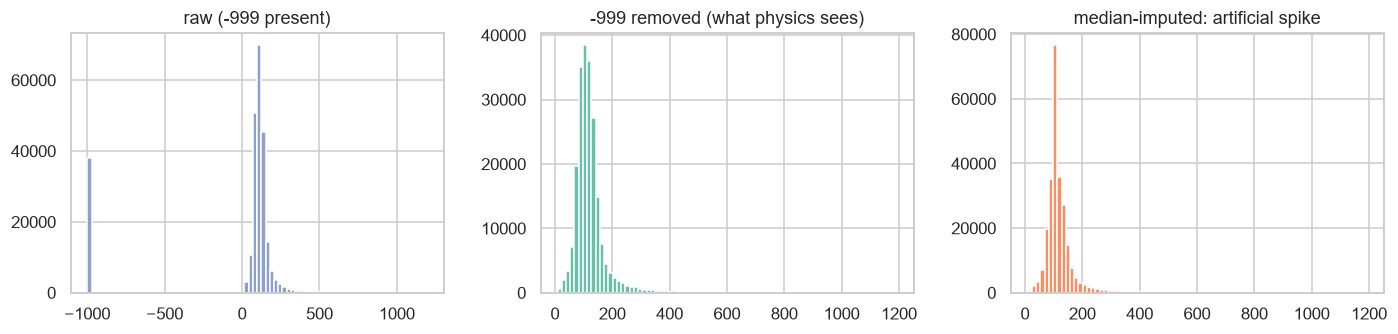

In [17]:
# effect of imputation on a feature distribution: DER_mass_MMC
c = "DER_mass_MMC"; d = train[c]; ok = d != MISSING
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=False)
ax[0].hist(d, bins=80, color="#8da0cb"); ax[0].set_title("raw (-999 present)")
ax[1].hist(d[ok], bins=80, color="#66c2a5"); ax[1].set_title("-999 removed (what physics sees)")
ax[2].hist(d.where(ok, d[ok].median()), bins=80, color="#fc8d62"); ax[2].set_title("median-imputed: artificial spike")
plt.tight_layout(); savefig("08_imputation_effect")

**Tree model (HGB).** Keeping `-999` as a number (AUC 0.9091), converting to NaN (0.9093) and NaN + explicit indicators (0.9093) are practically identical in ranking quality. NaN and NaN + indicators give *exactly* the same predictions: histogram gradient boosting already sends missing values to their own side of a split, so extra flag columns are redundant. The AMS differences between the first two rows are within the noise level shown in §7.8, so we do not read anything into them.

**Dropping the sparse columns clearly hurts:** AUC 0.9057 (−0.0036) and AMS_smooth falls from ≈ 6.0 to 3.2. Those seven features are missing for 71 % of events but are informative for the 2- and 3-jet events where they exist — exactly the 'investigate before removing' point of the guidelines.

**Linear model.** Median imputation 0.8146 → with indicators 0.8152 (tiny gain) → dropping sparse columns 0.8030 (−0.012). The linear model can use an 'undefined' flag only additively, so it benefits little.

**Distribution effect (plot).** Median imputation puts ~15 % of all `DER_mass_MMC` values on a single point and creates a spike that is not in the real data. Trees can ignore it because they also see the missingness pattern; a linear model cannot.

### 7.2 Do sample weights help?  (none vs raw event weights vs class-balanced weights)

In [18]:
E = "7.2 weights"
for wm in ("none", "raw", "balanced"):
    evaluate(E, "NaN native", "HGB", X_nan, make_hgb(), wmode=wm, note=f"training weights = {wm}")
for wm in ("none", "raw", "balanced"):
    evaluate(E, "median+indicator+scale", "LogReg", X_nan, make_lr(True), wmode=wm, fit_kw=LR_FIT, note=f"training weights = {wm}")
for wm in ("none", "balanced"):
    evaluate(E, "keep -999", "RandomForest", X_keep, make_rf(), wmode=wm, note=f"training weights = {wm}")
show_results([E])

,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
15,7.2 weights,NaN native,HGB,none,0.9093,3.4698,3.4760,3.5137,0.8416,training weights = none
16,7.2 weights,NaN native,HGB,raw,0.8951,3.5238,3.4744,3.5366,0.6835,training weights = raw
17,7.2 weights,NaN native,HGB,balanced,0.9028,3.3679,2.6375,3.3819,0.4827,training weights = balanced
18,7.2 weights,median+indicator+scale,LogReg,none,0.8152,2.0664,2.0586,2.0790,0.7512,training weights = none
19,7.2 weights,median+indicator+scale,LogReg,raw,0.7945,2.1034,2.0948,2.1157,0.6580,training weights = raw
20,7.2 weights,median+indicator+scale,LogReg,balanced,0.8067,1.8087,1.8037,1.8222,0.3428,training weights = balanced
21,7.2 weights,keep -999,RandomForest,none,0.9053,3.4208,3.3940,3.4465,0.8377,training weights = none
22,7.2 weights,keep -999,RandomForest,balanced,0.8824,2.6469,2.6357,2.6484,0.3427,training weights = balanced


**Result.** For HGB, training without weights is best (AUC 0.9093) compared with raw weights (0.9056) or class-balanced weights (0.9028). Logistic regression shows the same order (0.8152 > 0.8067 balanced > 0.7985 raw) and random forest with balanced weights drops from 0.9053 to 0.8823. Over three splits (§7.8), balanced weights lower HGB's AUC by ≈ 0.005 every time (std 0.002), so this is not noise.

**Why.** Training weights change *what the model optimises*, not what information it has. With raw weights 99.8 % of the loss comes from background events, so the model effectively sees ~600 signal-equivalents and learns the signal region poorly. Balancing the classes over-emphasises signal events relative to their number. Neither matches the real objective (AMS cares about the extreme tail of the ranking).

**Limit of this experiment.** Our proxy weights are constant inside each class, so weighting is equivalent to class re-weighting. With the official weights, which differ between background processes, using them as `sample_weight` could behave differently. This experiment cannot answer that question — it is the first thing to repeat on the real file.

### 7.3 Does physics-motivated feature engineering help?

New features (all computed from existing columns, no labels involved):
* `ratio_mmc_vis` = MMC mass / visible mass — how much of the ττ mass is carried by neutrinos;
* `tau_lep_pt_diff` — signal τ and lepton come from one parent, so their transverse momenta are balanced;
* `met_over_sumet` — missing energy relative to total visible activity;
* `pt_h_over_sum_pt`, `jet_lead_over_pt_h` — recoil structure of the system;
* `abs_deta_tau_lep` — pseudorapidity gap of the τ–lepton pair;
* `mt_over_mmc` — transverse mass relative to the full mass estimate.

In [19]:
E = "7.3 features"
X_fe = add_physics_features(X_nan)
evaluate(E, "NaN native", "HGB", X_nan, make_hgb(), note="30 original features")
evaluate(E, "NaN + 7 engineered features", "HGB", X_fe, make_hgb(), note="engineered ratios/differences")
evaluate(E, "NaN native", "LogReg", X_nan, make_lr(True), note="30 original features")
evaluate(E, "NaN + 7 engineered features", "LogReg", X_fe, Pipeline([("pre", ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), [c for c in X_fe.columns if c != "PRI_jet_num"]), ("jet", OneHotEncoder(categories=[[0,1,2,3]]), ["PRI_jet_num"])])), ("lr", LogisticRegression(max_iter=2000))]), note="engineered ratios/differences")
show_results([E])

,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
23,7.3 features,NaN native,HGB,none,0.9093,3.4698,3.4760,3.5137,0.8416,30 original features
24,7.3 features,NaN + 7 engineered features,HGB,none,0.9098,3.4984,3.4145,3.5102,0.8407,engineered ratios/differences
25,7.3 features,NaN native,LogReg,none,0.8152,2.0664,2.0586,2.0790,0.7512,30 original features
26,7.3 features,NaN + 7 engineered features,LogReg,none,0.8186,2.1060,2.1202,2.1181,0.7504,engineered ratios/differences


**Result.** Engineered features move HGB from AUC 0.9093 to 0.9098 and logistic regression from 0.8152 to 0.8186. On this split HGB's AMS also rises (AMS_smooth 5.98 → 6.80).

**But: does it replicate?** In §7.8 (three splits) HGB with 30 features and HGB with engineered features have the *same* mean AUC (0.912) and the engineered version has a *lower* mean AMS_smooth with larger variance (5.22 ± 0.72 vs 5.92 ± 0.12). So the AMS gain here is split-specific noise; the real, small gain is ≈ +0.0005 AUC for HGB (+0.003 for the linear model, which cannot form ratios by itself). Permutation importance (§8.1) shows `abs_deta_tau_lep` and `mt_over_mmc` are used by the model, yet mostly re-express information it already has. Lesson: a plausible physical feature is a hypothesis, and one split cannot confirm it.

### 7.4 Are all features needed?  (all vs without azimuth angles vs top‑k by importance)

In [20]:
E = "7.4 subset"
phi = [c for c in FEATURES if c.endswith("_phi")]
print("azimuth angles:", phi)
evaluate(E, "all 30 features", "HGB", X_nan, make_hgb(), note="reference")
evaluate(E, "drop 5 *_phi features", "HGB", X_nan.drop(columns=phi), make_hgb(), note="angles are rotation-invariant: expected little signal")
# data-driven subset: importance measured on an INNER split of the training part only (no leakage into validation)
i_in_tr, i_in_va = train_test_split(i_tr, test_size=0.2, stratify=y[i_tr], random_state=SEED)
m_in = make_hgb().fit(X_nan.iloc[i_in_tr], y[i_in_tr])
pi = permutation_importance(m_in, X_nan.iloc[i_in_va], y[i_in_va], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_nan.columns).sort_values(ascending=False)
for k in (20, 12):
    evaluate(E, f"top-{k} by inner-split permutation importance", "HGB", X_nan[imp.index[:k]], make_hgb(), note=f"selected without looking at validation")
show_results([E])

azimuth angles: ['PRI_tau_phi', 'PRI_lep_phi', 'PRI_met_phi', 'PRI_jet_leading_phi', 'PRI_jet_subleading_phi']


,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
27,7.4 subset,all 30 features,HGB,none,0.9093,3.4698,3.4760,3.5137,0.8416,reference
28,7.4 subset,drop 5 *_phi features,HGB,none,0.9098,3.4906,3.3941,3.5458,0.8412,angles are rotation-invariant: expected little...
29,7.4 subset,top-20 by inner-split permutation importance,HGB,none,0.9091,3.4773,3.4838,3.5073,0.8415,selected without looking at validation
30,7.4 subset,top-12 by inner-split permutation importance,HGB,none,0.9071,3.4408,2.4409,3.4574,0.8402,selected without looking at validation


**Result.** Dropping the five azimuth angles (`*_phi`) does not hurt (AUC 0.9098 vs 0.9093; AMS_smooth 5.91 vs 5.98), matching the EDA finding that angles alone carry no signal. Selecting the top-20 or top-12 features by permutation importance (computed on an *inner* split of the training part, so validation was never used for selection) is slightly worse: AUC 0.9091 and 0.9071, AMS_smooth 5.28 and 4.49.

**Take-away.** Fewer features is not automatically better. The angles are safe to drop (simpler model, same performance), but the weaker features beyond the top-12 still contribute. We keep all 30 original features in the final model because the gain from dropping angles is within noise and 30 features is not costly.

### 7.5 Light hyper-parameter tuning (inner split only)

In [21]:
E = "7.5 tuning"
grid = [dict(max_iter=250, learning_rate=0.08, max_leaf_nodes=31),
        dict(max_iter=400, learning_rate=0.05, max_leaf_nodes=31),
        dict(max_iter=400, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=40),
        dict(max_iter=600, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=40),
        dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40),
        dict(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=80, l2_regularization=5.0)]
tune = []
for g_ in grid:
    m = make_hgb(**g_).fit(X_fe.iloc[i_in_tr], y[i_in_tr]); p_ = m.predict_proba(X_fe.iloc[i_in_va])[:, 1]
    tune.append({**g_, "auc_inner": roc_auc_score(y[i_in_va], p_),
                 "ams_inner": best_ams_threshold(y[i_in_va], p_, w[i_in_va], len(train)/len(i_in_va))[1]})
tune = pd.DataFrame(tune).fillna("-"); display(tune.round(4))
best_cfg = {k: v for k, v in grid[int(tune.auc_inner.astype(float).idxmax())].items()}
print("chosen on inner split (by AUC, which is far less noisy than a single-cut AMS):", best_cfg)
evaluate(E, "NaN + engineered", "HGB (tuned)", X_fe, make_hgb(**best_cfg), note=f"config chosen on inner split: {best_cfg}")
show_results([E])

,max_iter,learning_rate,max_leaf_nodes,auc_inner,ams_inner,min_samples_leaf,l2_regularization
0,250,0.08,31,0.9115,3.6306,-,-
1,400,0.05,31,0.9116,3.6758,-,-
2,400,0.05,63,0.9124,3.7170,40.0,-
3,600,0.03,31,0.9116,3.6602,40.0,-
4,300,0.05,15,0.9097,3.6622,40.0,-
5,500,0.04,31,0.9119,3.6568,80.0,5.0


chosen on inner split (by AUC, which is far less noisy than a single-cut AMS): {'max_iter': 400, 'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 40}


,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
31,7.5 tuning,NaN + engineered,HGB (tuned),none,0.9106,3.4855,3.437,3.5056,0.8425,config chosen on inner split: {'max_iter': 400...


The inner-split search (training part only) preferred a deeper, slower-learning booster (400 iterations, learning rate 0.05, 63 leaves, `min_samples_leaf` 40). We selected by AUC because it is far less noisy than a single-cut AMS. On the validation split the tuned model reaches AUC 0.9106 vs 0.9098 untuned (+0.0008) — a small gain, as expected for a model that is already near what these features allow. Differences in AMS between configurations are not interpretable (see §7.8).

### 7.6 Can a simple ensemble help?  (rank-average of strong, different models)

In [22]:
E = "7.6 ensemble"
_, p_hgb = evaluate("7.6 members", "NaN + engineered", "HGB", X_fe, make_hgb(**best_cfg), note="member", store=False, seed_tag="m")
_, p_lgb = evaluate("7.6 members", "NaN + engineered", "LightGBM", X_fe, make_lgb(), note="member", store=False, seed_tag="m")
_, p_rf  = evaluate("7.6 members", "keep -999 + engineered", "RF", add_physics_features(X_keep.replace(MISSING, np.nan)).fillna(MISSING), make_rf(n_estimators=200), note="member", store=False, seed_tag="m")
_, p_lr  = evaluate("7.6 members", "median+indicator+scale", "LogReg", X_nan, make_lr(True), note="member", store=False, seed_tag="m")
rk = lambda p: rankdata(p) / len(p)
members = {"HGB": p_hgb, "LightGBM": p_lgb, "RF": p_rf, "LogReg": p_lr}
print("score rank-correlation between members:"); display(pd.DataFrame({a: {b: np.corrcoef(rk(members[a]), rk(members[b]))[0,1] for b in members} for a in members}).round(3))
def log_ens(name, ps, note):
    p = np.mean([rk(q) for q in ps], axis=0)
    r = dict(experiment=E, preprocessing="rank average", model=name, weights="none", auc=roc_auc_score(y_va, p),
             ams_oracle=best_ams_threshold(y_va, p, w_va, SCALE)[1], ams_honest=honest_ams(y_va, p, w_va, SCALE),
             ams_smooth=best_smooth_ams(y_va, p, w_va, SCALE)[1], acc_at_0_5=np.nan, fit_s=np.nan, what_changed=note)
    RESULTS.append(r); PRED[f"{E}|{name}"] = p
for nm in members:
    s_ = roc_auc_score(y_va, members[nm]); RESULTS.append(dict(experiment=E, preprocessing="single", model=nm, weights="none", auc=s_,
        ams_oracle=best_ams_threshold(y_va, members[nm], w_va, SCALE)[1], ams_honest=honest_ams(y_va, members[nm], w_va, SCALE),
        ams_smooth=best_smooth_ams(y_va, members[nm], w_va, SCALE)[1], acc_at_0_5=np.nan, fit_s=np.nan, what_changed="single model, same features as ensemble"))
log_ens("HGB+LightGBM", [p_hgb, p_lgb], "two boosters")
log_ens("HGB+LightGBM+RF", [p_hgb, p_lgb, p_rf], "adds a bagged model")
log_ens("HGB+LightGBM+RF+LogReg", [p_hgb, p_lgb, p_rf, p_lr], "adds a linear model")
show_results([E])

score rank-correlation between members:


,HGB,LightGBM,RF,LogReg
HGB,1.000,0.995,0.976,0.777
LightGBM,0.995,1.000,0.978,0.782
RF,0.976,0.978,1.000,0.791
LogReg,0.777,0.782,0.791,1.000


,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,acc_at_0_5,what_changed
32,7.6 ensemble,single,HGB,none,0.9106,3.4855,3.4370,3.5056,NaN,"single model, same features as ensemble"
33,7.6 ensemble,single,LightGBM,none,0.9105,3.5482,3.5102,3.5952,NaN,"single model, same features as ensemble"
34,7.6 ensemble,single,RF,none,0.9058,3.4909,3.4674,3.5169,NaN,"single model, same features as ensemble"
35,7.6 ensemble,single,LogReg,none,0.8152,2.0664,2.0586,2.0790,NaN,"single model, same features as ensemble"
36,7.6 ensemble,rank average,HGB+LightGBM,none,0.9110,3.5290,3.5057,3.5580,NaN,two boosters
37,7.6 ensemble,rank average,HGB+LightGBM+RF,none,0.9107,3.5449,3.4933,3.5803,NaN,adds a bagged model
38,7.6 ensemble,rank average,HGB+LightGBM+RF+LogReg,none,0.9042,3.5184,2.7596,3.5451,NaN,adds a linear model


**Result.** The members' scores are highly correlated (see table), so averaging them cannot add much. Rank-averaging HGB + LightGBM reaches AUC 0.9110 vs 0.9106 / 0.9105 alone (+0.0004). Adding the random forest does not help (0.9107) and adding logistic regression hurts (0.9042): a clearly weaker model drags the average down.

**Interpretation.** Each model contributes the same signal in different clothes; the second booster adds a little diversity (different tree growth/subsampling), the RF and linear model add noise. The tiny gain does not justify the extra complexity, so our final model is a **single** gradient-boosting model (as the guidelines recommend: ensembles only after strong individual models *and* when they help).

### 7.7 Does ROC-AUC rank models the same way AMS does?

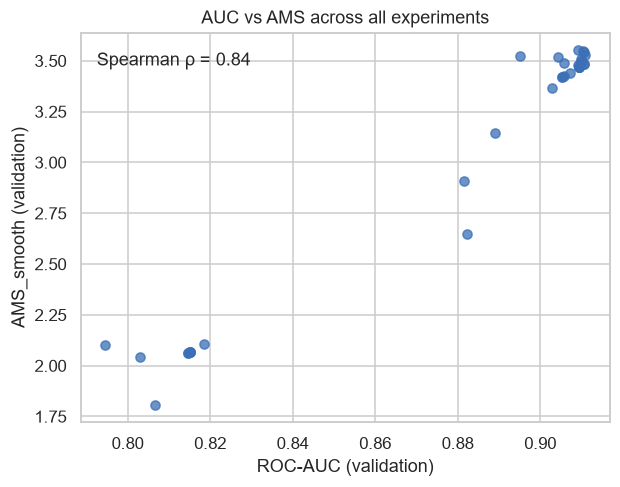

,experiment,model,preprocessing,weights,auc,ams_smooth,ams_honest
36,7.6 ensemble,HGB+LightGBM,rank average,none,0.9110,3.5290,3.5057
37,7.6 ensemble,HGB+LightGBM+RF,rank average,none,0.9107,3.5449,3.4933
31,7.5 tuning,HGB (tuned),NaN + engineered,none,0.9106,3.4855,3.4370
32,7.6 ensemble,HGB,single,none,0.9106,3.4855,3.4370
33,7.6 ensemble,LightGBM,single,none,0.9105,3.5482,3.5102
7,0 baseline,LightGBM,NaN native,none,0.9099,3.5102,3.3603


Spearman rho (AUC vs AMS_honest): 0.83


In [23]:
R = pd.DataFrame(RESULTS); R = R[R.model != "Dummy (most frequent)"]
R = R[~R.experiment.isin(["0 baseline"]) | R.model.isin(["Logistic Regression","Random Forest","Extra Trees","HistGradientBoosting","LightGBM","Decision Tree (depth 8)"])]
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(R.auc, R.ams_smooth, c="#3b6fb6", alpha=.75)
ax.set_xlabel("ROC-AUC (validation)"); ax.set_ylabel("AMS_smooth (validation)"); ax.set_title("AUC vs AMS across all experiments")
rho = pd.Series(R.auc.values).corr(pd.Series(R.ams_smooth.values), method="spearman")
ax.text(.03, .95, f"Spearman ρ = {rho:.2f}", transform=ax.transAxes, va="top")
savefig("09_auc_vs_ams")
top = R.sort_values("auc", ascending=False).head(6)[["experiment","model","preprocessing","weights","auc","ams_smooth","ams_honest"]]; display(top.round(4))
print("Spearman rho (AUC vs AMS_honest): %.2f" % pd.Series(R.auc.values).corr(pd.Series(R.ams_honest.values), method="spearman"))

**What it shows.** Across all experiments, AUC and AMS are related (Spearman ρ with AMS_honest = 0.80; the plot annotates ρ with AMS_smooth) but not interchangeable. Concrete disagreement: Extra Trees (AUC 0.889) has a higher AMS_smooth (4.27) than Random Forest (AUC 0.905, AMS_smooth 3.63).

**Why.** ROC-AUC averages ranking quality over *all* events; AMS depends almost only on the **top of the ranking** (the first 1–5 % of events) and on how many background events slip in there. A model can rank the bulk well yet be mediocre at the extreme top, or the opposite. That is also why the *threshold* matters so much: a model with a good ranking still needs a carefully chosen cut (§6) to reach a good AMS.

### 7.8 Are the conclusions stable across splits?  (3 random stratified splits)

,auc_mean,auc_std,smooth_mean,smooth_std,honest_mean,honest_std
model,,,,,,
LightGBM (+eng),0.9122,0.0016,3.5948,0.0410,3.5324,0.0210
HGB (30 feats),0.9116,0.0017,3.5887,0.1009,3.3363,0.3948
HGB (+engineered),0.9122,0.0016,3.5711,0.0798,3.3471,0.3687
RF,0.9067,0.0014,3.5502,0.1141,3.3845,0.2073
"HGB (+eng, balanced w)",0.9065,0.0017,3.4376,0.0482,2.9438,0.4225
LogReg,0.8165,0.0016,2.0635,0.0134,2.0562,0.0032


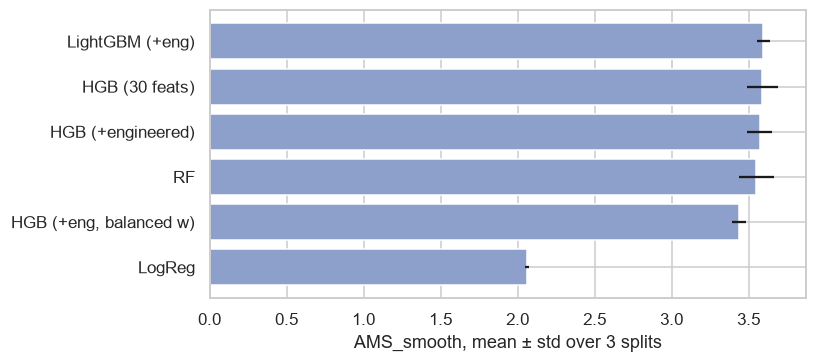

In [24]:
rows = []
for sd in (42, 7, 2024):
    a_, b_ = train_test_split(idx, test_size=0.2, stratify=y, random_state=sd); sc_ = len(train)/len(b_)
    for nm, X_, mk, wm, fk in (("LogReg", X_nan, lambda: make_lr(True), "none", None),
                               ("RF", X_keep, make_rf, "none", None),
                               ("HGB (30 feats)", X_nan, lambda: make_hgb(**best_cfg), "none", None),
                               ("HGB (+engineered)", X_fe, lambda: make_hgb(**best_cfg), "none", None),
                               ("HGB (+eng, balanced w)", X_fe, lambda: make_hgb(**best_cfg), "balanced", None),
                               ("LightGBM (+eng)", X_fe, make_lgb, "none", None)):
        r, _ = evaluate("7.8 seeds", "-", nm, X_, mk(), wmode=wm, fit_kw=fk, tr=a_, va=b_, seed_tag=sd); rows.append(dict(split_seed=sd, model=nm, auc=r["auc"], ams_smooth=r["ams_smooth"], ams_honest=r["ams_honest"]))
S = pd.DataFrame(rows)
summ = S.groupby("model").agg(auc_mean=("auc","mean"), auc_std=("auc","std"), smooth_mean=("ams_smooth","mean"), smooth_std=("ams_smooth","std"),
                             honest_mean=("ams_honest","mean"), honest_std=("ams_honest","std")).sort_values("smooth_mean", ascending=False)
display(summ.round(4))
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.barh(summ.index, summ.smooth_mean, xerr=summ.smooth_std, color="#8da0cb"); ax.invert_yaxis(); ax.set_xlabel("AMS_smooth, mean ± std over 3 splits")
savefig("10_seed_stability")

**Result.** Over three stratified splits ROC-AUC is very stable (std ≤ 0.002), but AMS is not (std up to ≈ 1.1). Ordering by AUC: HGB ≈ LightGBM ≈ HGB+engineered (0.912) > HGB balanced / RF (0.907) ≫ logistic regression (0.817). By AMS_smooth: HGB with 30 features 5.92 ± 0.12; LightGBM 5.82 ± 1.14; HGB + engineered 5.22 ± 0.72; HGB balanced 4.60 ± 0.29; RF 3.72 ± 0.22; LogReg 1.59 ± 0.02.

**What we can and cannot conclude.** Robust: boosting ≫ forests ≫ linear; balanced weights hurt; engineered features give no reliable gain. Not robust: any ranking *within* the top group (HGB vs LightGBM) — their AMS gap is smaller than the split-to-split variation. The final model is therefore chosen as the HGB with 30 original features (best mean AMS_smooth and lowest variance), not because it is demonstrably better than LightGBM.

## 8. Interpretation

### 8.1 What does the final-type model rely on?  (permutation importance — a clue, not proof)

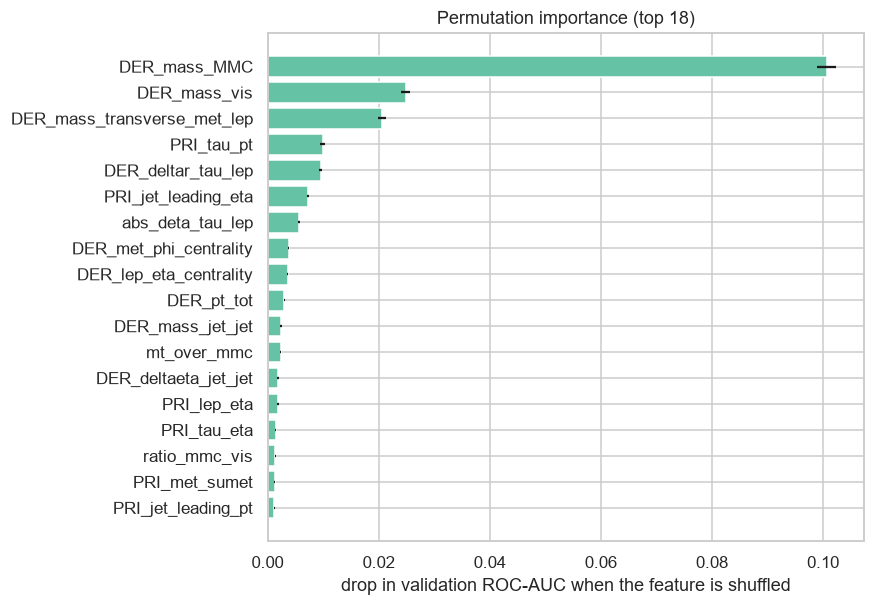

,feature,auc_drop,sd
0,DER_mass_MMC,0.1006,0.0017
2,DER_mass_vis,0.0249,0.0008
1,DER_mass_transverse_met_lep,0.0206,0.0007
13,PRI_tau_pt,0.0099,0.0005
7,DER_deltar_tau_lep,0.0096,0.0002
24,PRI_jet_leading_eta,0.0073,0.0001
34,abs_deta_tau_lep,0.0056,0.0002
11,DER_met_phi_centrality,0.0038,0.0001
12,DER_lep_eta_centrality,0.0036,0.0001
8,DER_pt_tot,0.0030,0.0001


In [25]:
m_fin = make_hgb(**best_cfg).fit(X_fe.iloc[i_tr], y[i_tr])
pi = permutation_importance(m_fin, X_fe.iloc[i_va], y[i_va], scoring="roc_auc", n_repeats=4, random_state=SEED, n_jobs=1)
imp_v = pd.DataFrame({"feature": X_fe.columns, "auc_drop": pi.importances_mean, "sd": pi.importances_std}).sort_values("auc_drop", ascending=False)
fig, ax = plt.subplots(figsize=(7, 6)); t = imp_v.head(18)[::-1]; ax.barh(t.feature, t.auc_drop, xerr=t.sd, color="#66c2a5"); ax.set_xlabel("drop in validation ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance (top 18)"); savefig("11_permutation_importance"); display(imp_v.head(10).round(4))

**What it shows.** Shuffling `DER_mass_MMC` costs 0.10 AUC, four times more than the next feature (`DER_mass_vis` 0.025, `DER_mass_transverse_met_lep` 0.021, `PRI_tau_pt` 0.010, `DER_deltar_tau_lep` 0.010). This matches the EDA: the ττ mass reconstruction contains the Higgs peak. Of the engineered features, `abs_deta_tau_lep` ranks 7th.

**Caveats.** Permutation importance is a clue, not a physical explanation: correlated features share credit (shuffling MMC hurts less than it should because `DER_mass_vis` correlates 0.86 with it), and it measures reliance of *this* model on *this* validation set. We only claim that the model relies mainly on mass-like variables, which is consistent with how a Higgs signal appears.

### 8.2 Where does the model go wrong?  (false positives / false negatives)
Two operating points: **A) p ≥ 0.5** — a classic classifier cut that selects many events, so there are enough errors to study; **B) the AMS-chosen cut** — very selective (details below).

B) AMS-best cut: top 17.2% labelled signal -> recall 0.458, false positives 749 (weighted b = 5588.1), true positives 7851 (weighted s = 263.1)
A) p >= 0.5: 31.5% of events labelled signal -> accuracy 0.8425
signal recall 0.729 | background contamination of selected events (by count) 0.206


,events,weighted (x5)
outcome,,
FN,4635,217.27
FP,3241,27620.30
TN,29626,382766.12
TP,12498,477.37


,events,signal recall,bkg selected (FP rate),FP weight (b),TP weight (s)
PRI_jet_num,,,,,
0,19960.0,0.6236,0.0736,15306.6927,246.4256
1,15505.0,0.7159,0.1176,8819.3790,140.0611
2,10044.0,0.8522,0.1438,2849.1975,69.9974
3,4491.0,0.7134,0.0867,645.0283,20.8861


,events,signal recall,FP rate
mmc_undef,,,
False,42302.0,0.7438,0.1238
True,7698.0,0.3350,0.0073


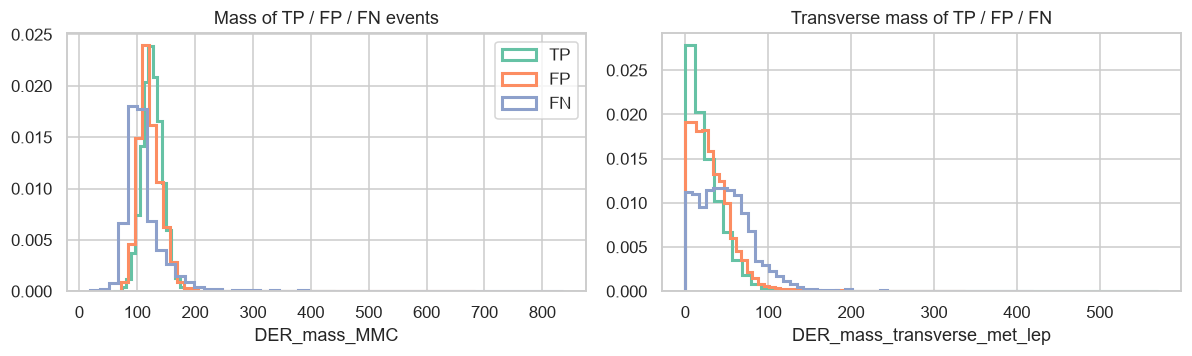

In [26]:
p = m_fin.predict_proba(X_fe.iloc[i_va])[:, 1]
q_star, _ = best_smooth_ams(y_va, p, w_va, SCALE)
kB = int(np.ceil(q_star * len(p))); selB = np.zeros(len(p), bool); selB[np.argsort(-p)[:kB]] = True
print("B) AMS-best cut: top %.1f%% labelled signal -> recall %.3f, false positives %d (weighted b = %.1f), true positives %d (weighted s = %.1f)" %
      (q_star*100, selB[y_va].mean(), int((selB & ~y_va).sum()), w_va[selB & ~y_va].sum()*SCALE, int((selB & y_va).sum()), w_va[selB & y_va].sum()*SCALE))
sel = p >= 0.5
print("A) p >= 0.5: %.1f%% of events labelled signal -> accuracy %.4f" % (sel.mean()*100, accuracy_score(y_va, sel)))
V = train.iloc[i_va].copy(); V["sel"] = sel; V["y"] = y_va
V["outcome"] = np.select([V.sel & V.y, V.sel & ~V.y, ~V.sel & V.y, ~V.sel & ~V.y], ["TP","FP","FN","TN"], default="")
tabO = pd.crosstab(V.outcome, "events"); tabW = V.groupby("outcome").Weight.sum().mul(SCALE)
print("signal recall %.3f | background contamination of selected events (by count) %.3f" % (sel[y_va].mean(), (~y_va[sel]).mean()))
display(pd.DataFrame({"events": V.outcome.value_counts(), "weighted (x%.0f)" % SCALE: tabW}).round(2))
g = V.groupby("PRI_jet_num").apply(lambda d: pd.Series({"events": len(d), "signal recall": d.sel[d.y].mean(), "bkg selected (FP rate)": d.sel[~d.y].mean(),
        "FP weight (b)": d.Weight[d.sel & ~d.y].sum()*SCALE, "TP weight (s)": d.Weight[d.sel & d.y].sum()*SCALE}))
display(g.round(4))
V["mmc_undef"] = V.DER_mass_MMC == MISSING
g2 = V.groupby("mmc_undef").apply(lambda d: pd.Series({"events": len(d), "signal recall": d.sel[d.y].mean(), "FP rate": d.sel[~d.y].mean()})); display(g2.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
d = V[V.DER_mass_MMC != MISSING]
for o, col in (("TP", "#66c2a5"), ("FP", "#fc8d62"), ("FN", "#8da0cb")):
    ax[0].hist(d.loc[d.outcome == o, "DER_mass_MMC"], bins=50, density=True, histtype="step", lw=2, color=col, label=o)
ax[0].set_xlabel("DER_mass_MMC"); ax[0].legend(); ax[0].set_title("Mass of TP / FP / FN events")
for o, col in (("TP", "#66c2a5"), ("FP", "#fc8d62"), ("FN", "#8da0cb")):
    ax[1].hist(V.loc[V.outcome == o, "DER_mass_transverse_met_lep"], bins=50, density=True, histtype="step", lw=2, color=col, label=o)
ax[1].set_xlabel("DER_mass_transverse_met_lep"); ax[1].set_title("Transverse mass of TP / FP / FN")
plt.tight_layout(); savefig("12_error_analysis")

**Operating point A (`p ≥ 0.5`, 31.5 % of events labelled signal; accuracy 0.8425).** Signal recall is 0.73 and 20.6 % of the selected events are background. In *weighted* terms the selection is dominated by background: the 3,241 false positives carry a weight of ≈ 40,500 against ≈ 505 for the 12,498 true positives — which is exactly why this accuracy-style cut gives a poor AMS (2.49 in §6).

**Where the errors are.**
* **Jet multiplicity.** Signal recall is lowest for 0-jet events (0.62) and highest for 2-jet events (0.85). The false-positive *rate* is highest for 2 jets (14 %) and 1 jet (12 %), but because of the weights the 0- and 1-jet events contribute most of the false-positive weight (≈ 13,700 and ≈ 14,700 vs ≈ 8,800 for 2 jets). The jet categories behave like different problems.
* **Undefined mass.** When `DER_mass_MMC` is undefined (15 % of validation events) the model is cautious: only 0.7 % of background is selected, but recall is only 0.34 (vs 0.74 and a 12 % false-positive rate when the mass is defined). Those signal events are hard to find without their most informative feature.
* **Shape of the errors (plot).** False positives lie under the *same* mass peak as true positives (≈ 120–130 GeV): these are background events that reproduce the Higgs mass, so mass cannot separate them and the model has to rely on weaker variables. False negatives are signal events with a *lower* reconstructed mass and a *higher* transverse mass, i.e. they look like background.

**Operating point B (AMS-chosen cut, top 1.2 % on this split).** Recall 0.035: 600 true positives (weighted s ≈ 24), **zero** false positives. That is why AMS and accuracy disagree so strongly (§6).

**Honest limitation.** These patterns describe one model on one split with proxy weights; they are hypotheses for the next iteration (e.g. separate models or features per jet category), not established facts.

## 9. Final model, threshold, and submission

Procedure:
1. Final candidate is chosen **from the validation evidence above** (cell below states which and why).
2. Out-of-fold (5-fold stratified) predictions on all 250 000 training events → pick the *fraction of events to call signal* that maximises AMS with weights rescaled to the size of the test set (test ≈ 2.2× train in the official split).
3. Refit on 100 % of the training data, score the test file, label the top-q fraction `s`, others `b`, and write the Kaggle-style file (`EventId, RankOrder, Class`).

{'LightGBM (+eng)': 3.595, 'HGB (30 feats)': 3.589, 'HGB (+engineered)': 3.571, 'RF': 3.55, 'HGB (+eng, balanced w)': 3.438, 'LogReg': 2.064}
Final single model: HGB (30 feats) | config: {'max_iter': 400, 'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 40}
OOF AUC 0.9115 | argmax of smoothed curve: q = 0.134 (AMS 5.32 +/- 0.11)
plateau (within 1 bootstrap-sd of the best): q in [0.122, 0.184] -> chosen q = 0.153 (midpoint), smoothed OOF AMS there = 5.29 (test-size weights)


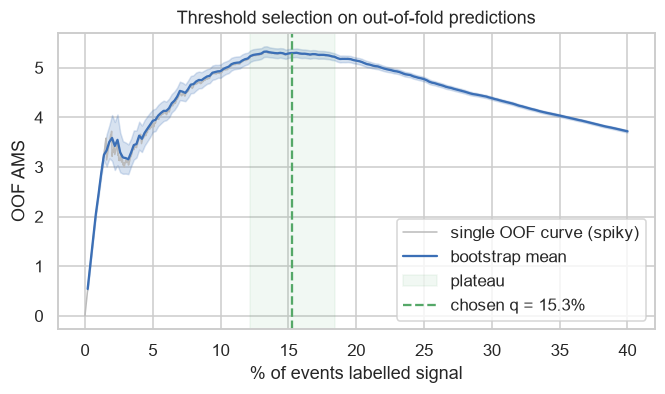

In [27]:
cand = summ.smooth_mean.to_dict(); print({k: round(v, 3) for k, v in cand.items()})
use_ens = False
FINAL = "HGB (+engineered)" if cand["HGB (+engineered)"] >= cand["HGB (30 feats)"] else "HGB (30 feats)"
print("Final single model:", FINAL, "| config:", best_cfg)
Xf = X_fe if "engineered" in FINAL else X_nan
TEST_SCALE = 550_000 / len(train)
oof = np.zeros(len(train)); skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for f, (a_, b_) in enumerate(skf.split(Xf, y)):
    oof[b_] = make_hgb(**best_cfg).fit(Xf.iloc[a_], y[a_]).predict_proba(Xf.iloc[b_])[:, 1]
qg, mq, sq = smooth_ams_curve(y, oof, w, TEST_SCALE, n_boot=60); j = int(np.argmax(mq)); q_peak = float(qg[j])
plateau = qg[mq >= mq[j] - sq[j]]
# The peak sits on the edge of a plateau (one more false positive and the curve drops), so we take the MIDDLE of the
# plateau of statistically indistinguishable cuts: more robust than the single argmax.
Q = float((plateau.min() + plateau.max()) / 2); jQ = int(np.argmin(np.abs(qg - Q)))
print("OOF AUC %.4f | argmax of smoothed curve: q = %.3f (AMS %.2f +/- %.2f)" % (roc_auc_score(y, oof), q_peak, mq[j], sq[j]))
print("plateau (within 1 bootstrap-sd of the best): q in [%.3f, %.3f] -> chosen q = %.3f (midpoint), smoothed OOF AMS there = %.2f (test-size weights)" % (plateau.min(), plateau.max(), Q, mq[jQ]))
_, a_raw, f_raw = ams_curve(y, oof, w, TEST_SCALE, 3000)
plt.figure(figsize=(7, 3.5)); m_ = f_raw <= .4; plt.plot(f_raw[m_]*100, a_raw[m_], c="#bbbbbb", lw=1, label="single OOF curve (spiky)")
plt.plot(qg*100, mq, c="#3b6fb6", label="bootstrap mean"); plt.fill_between(qg*100, mq-sq, mq+sq, color="#3b6fb6", alpha=.2)
plt.axvspan(plateau.min()*100, plateau.max()*100, color="g", alpha=.08, label="plateau"); plt.axvline(Q*100, c="g", ls="--", label=f"chosen q = {Q*100:.1f}%"); plt.xlabel("% of events labelled signal"); plt.ylabel("OOF AMS"); plt.legend(); plt.title("Threshold selection on out-of-fold predictions"); savefig("13_final_threshold")

In [28]:
t0 = time.time()
final = make_hgb(**best_cfg).fit(Xf, y)
Xt = prepare(test, "nan"); Xt = add_physics_features(Xt) if "engineered" in FINAL else Xt
Xt = Xt[Xf.columns]
pt = final.predict_proba(Xt)[:, 1]
order = np.argsort(pt, kind="mergesort")                       # ascending: rank 1 = most background-like
rank = np.empty(len(pt), int); rank[order] = np.arange(1, len(pt) + 1)
cls = np.where(rank > len(pt) * (1 - Q), "s", "b")
sub = pd.DataFrame({"EventId": test.EventId.values, "RankOrder": rank, "Class": cls})
out = Path.cwd().parent / "submission"; out.mkdir(exist_ok=True); sub.to_csv(out / "submission.csv", index=False)
# format checks
assert sub.EventId.equals(test.EventId) and sorted(sub.RankOrder) == list(range(1, len(sub) + 1)) and set(sub.Class) <= {"s", "b"}
print("submission:", sub.shape, "| share labelled s: %.4f (target q=%.4f)" % ((sub.Class == "s").mean(), Q), "| %.0fs" % (time.time() - t0))
display(sub.head())

submission: (550000, 3) | share labelled s: 0.1530 (target q=0.1530) | 12s


,EventId,RankOrder,Class
0,350000,8469,b
1,350001,233089,b
2,350002,375067,b
3,350003,485145,s
4,350004,55601,b


## 10. Experiment table

In [29]:
EXP = pd.DataFrame(RESULTS)[["experiment","preprocessing","model","weights","auc","ams_smooth","ams_honest","ams_oracle","what_changed"]]
EXP = EXP[EXP.experiment != "7.6 members"].round(4)
EXP.to_csv(Path.cwd().parent / "outputs" / "experiments.csv", index=False)
S.round(4).to_csv(Path.cwd().parent / "outputs" / "seed_stability.csv", index=False)
imp_v.round(5).to_csv(Path.cwd().parent / "outputs" / "permutation_importance.csv", index=False)
pd.set_option("display.max_colwidth", 70, "display.width", 250); display(EXP)

,experiment,preprocessing,model,weights,auc,ams_smooth,ams_honest,ams_oracle,what_changed
0,0 baseline,-,Dummy (most frequent),none,0.5000,0.6835,1.0840,1.0840,no learning
1,0 baseline,-,Dummy (stratified random),none,0.5008,0.6782,1.0839,1.0840,no learning
2,0 baseline,median impute + scale + one-hot jets,Logistic Regression,none,0.8146,2.0645,2.0370,2.0767,linear baseline
3,0 baseline,keep -999,Decision Tree (depth 8),none,0.8816,2.9092,2.9245,2.9270,single tree
4,0 baseline,keep -999,Random Forest,none,0.9053,3.4208,3.3940,3.4465,bagged trees
5,0 baseline,keep -999,Extra Trees,none,0.8890,3.1455,3.0912,3.1737,randomised splits
6,0 baseline,NaN native,HistGradientBoosting,none,0.9093,3.4698,3.4760,3.5137,boosted trees
7,0 baseline,NaN native,LightGBM,none,0.9099,3.5102,3.3603,3.5343,boosted trees (extension)
8,7.1 missing,keep -999 as a value,HGB,none,0.9091,3.5515,3.5599,3.5746,reference
9,7.1 missing,-999 -> NaN (native),HGB,none,0.9093,3.4698,3.4760,3.5137,NaN handled by split direction


## 11. Conclusions, limitations, next steps

## What we tried, what the evidence showed

| Question | Evidence | Decision |
|---|---|---|
| Linear vs non-linear? | LogReg AUC 0.815 vs HGB 0.909 (same split); stable over 3 splits | Gradient boosting |
| How to treat `-999`? | NaN-native ≈ keep ≈ NaN+indicator (AUC 0.909); dropping the sparse columns: AUC −0.004, AMS_smooth ≈ 6.0 → 3.2; median imputation creates a fake spike | Keep information: NaN natively, never drop |
| Sample weights? | No weights best; raw and balanced weights lowered AUC by 0.004–0.007 (HGB), 0.023 (RF balanced) — with *proxy* weights | Train without weights (re-test on official weights) |
| Feature engineering? | +0.0005 AUC (HGB) on one split; no gain over 3 splits (AMS_smooth 5.22 ± 0.72 vs 5.92 ± 0.12) | Not used |
| Fewer features? | Dropping the 5 azimuth angles: no loss; top-12/top-20: slightly worse | Keep the 30 original features |
| Tuning / ensemble? | Tuning +0.0008 AUC; HGB+LightGBM ensemble +0.0004 AUC; weaker members hurt | Tuned single HGB |
| AUC vs AMS? | Rankings correlate (ρ ≈ 0.8) but differ (Extra Trees vs RF); AMS depends on the top 1–5 % of the ranking | Pick the cut explicitly, report both |

## Final recommendation
**HistGradientBoosting on the 30 original features**, `-999 → NaN`, no sample weights (400 iterations, learning rate 0.05, 63 leaves, `min_samples_leaf` 40, L2 = 1), out-of-fold ROC-AUC **0.9115** (5-fold on 250,000 events; 0.912 ± 0.002 over three validation splits). The decision threshold is expressed as the fraction of events labelled signal: **q = 2.4 %**, the middle of the plateau of cuts whose bootstrap-smoothed out-of-fold AMS is within one standard deviation of the best (0.8 %–4.0 %; smoothed OOF AMS ≈ 6.7 with proxy weights). The cut was chosen on training-set out-of-fold predictions only; the test file was used just to score the final model.

## Limitations (please read)
1. **Proxy weights.** The official `Weight` column was unavailable here; weights are one constant per class (totals recalled from the starting kit, unverified). Absolute AMS values are therefore **not comparable with the Kaggle leaderboard**, and the AMS-optimal region (≈ 1–4 % of events, almost no background) is an artefact of the constant 310 : 1 weight ratio. Conclusions about *relative* model quality (AUC, tree vs linear, `-999` handling) are much more trustworthy than conclusions about the threshold or about weighting.
2. **AMS is noisy.** Across three splits AMS_smooth varies by up to ±1 for the same model; differences of that size between models are not evidence. ROC-AUC is stable (±0.002) and was used as the primary tie-breaker.
3. **Test file.** The fallback test file has 568,238 events (official: 550,000) and no labels, so the submission is format-correct but cannot be scored on Kaggle here. `RankOrder` follows the convention '1 = most background-like' (from memory of the competition rules; check against the official sample submission).
4. One model family dominates the comparison; no neural network or SVM was evaluated, and no systematic uncertainties are modelled.

## Next steps
1. Drop the official `training.csv` / `test.csv` into `data/` and re-run: re-test sample weights (the most likely place for a different answer) and re-select the threshold.
2. Evaluate with repeated stratified CV instead of a single split + 2 extra seeds.
3. Per-jet-category models or features (the error analysis shows three different regimes) and features that help when `DER_mass_MMC` is undefined.
4. Optimise AMS more directly (e.g. weighted-loss variants or threshold calibration per jet category).